# Week 12 - Kernel Methods

Learning contents:
* Kernel Regression
    * Compute Gram Matrix
    * Estimate the target values for a new set of data points
    * Plot the (x_new, t_new)-pairs on top of the original data
    * Play around with the kernel $\sigma$. How does the fit look using $\sigma=1$ as compared to  $\sigma=10$?


In [71]:
# Dependencies
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme()


# 1) Kernel Regression

We'll be working with two variables from the [California Housing dataset](https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset):
median income (`MedInc`) as the input feature and median house value (`MedHouseVal`, in $100Ks) as the target.

The dataset is loaded via `sklearn.datasets.fetch_california_housing` (cached locally on first run).
We subsample 500 points (seeded for reproducibility) to keep the Gram matrix tractable on a laptop.

_Note: `MedHouseVal` is capped at 5.0 ($500K) in the source data — you will see this as a horizontal band of points at the top of the scatter plot. This is a real-data artifact, not a bug._

In [72]:
from sklearn.datasets import fetch_california_housing

cal = fetch_california_housing()
rng = np.random.default_rng(42)
idx = rng.choice(len(cal.data), 500, replace=False)

x = cal.data[idx, 0]  # MedInc: median income in the block group
t = cal.target[idx]   # MedHouseVal: median house value ($100Ks)

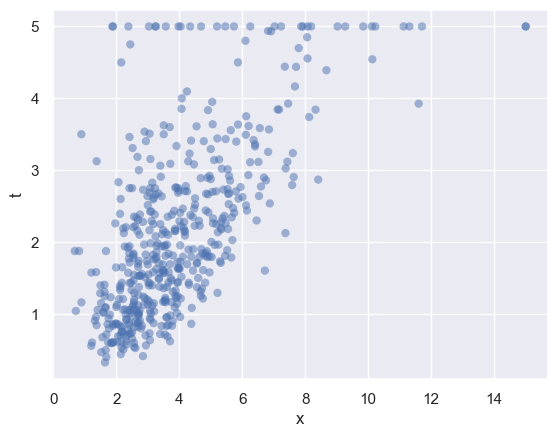

In [73]:
def plot_scatter(data, target, alpha=0.5, legend=True):
    scatter = plt.scatter(data, target,  edgecolor='none', alpha=alpha)
    plt.xlabel('x')
    plt.ylabel('t')

# Let's plot all the data in 2D
plot_scatter(x, t)

## 1.1) Compute the kernel gram matrix
Do it using the Gaussian Kernel based on Euclidean distance.

Use $\sigma = 2$

First, perform the computation for the 5 first samples. Then do it for all samples. What is the shape of the Gram matrix for all samples?

In [74]:
sigma = 2

print(x[:5])
differences = x[0] - x[:5]
kernel_gaussian_row1 = np.exp(-(differences**2) / (2 * sigma**2))

[ 7.2316  2.5172  2.6429  3.875  10.2233]


In [75]:
def gram_matrix(X1, X2=None, sigma=2):
    """
    Compute the kernel (Gram) matrix using the Gaussian/RBF kernel.

    Parameters
    ----------
    X1 : array of shape (n1,) or (n1, d)
    X2 : array of shape (n2,) or (n2, d), optional. If None, use X2 = X1.
    sigma : float, kernel bandwidth parameter

    Returns
    -------
    K : array of shape (n1, n2), where
        K[i, j] = exp(-||X1[i] - X2[j]||^2 / (2 * sigma^2)).
    """
    X1 = np.asarray(X1)
    if X1.ndim == 1:
        X1 = X1.reshape(-1, 1)

    if X2 is None:
        X2 = X1
    else:
        X2 = np.asarray(X2)
        if X2.ndim == 1:
            X2 = X2.reshape(-1, 1)

    if X1.shape[1] != X2.shape[1]:
        raise ValueError("X1 and X2 must have the same number of features")

    kernel_gram_matrix = np.empty((len(X1), len(X2)))
    for i in range(len(X1)):
        differences = X1[i] - X2
        squared_distances = np.sum(differences**2, axis=1)
        kernel_gram_matrix[i, :] = np.exp(-squared_distances / (2 * sigma**2))

    return kernel_gram_matrix


# Compute Gram matrix for the first 5 samples
gram_matrix(x[:5], sigma=sigma)


array([[1.00000000e+00, 6.21505308e-02, 7.19329416e-02, 2.44547566e-01,
        3.26676919e-01],
       [6.21505308e-02, 1.00000000e+00, 9.98026888e-01, 7.94174074e-01,
        5.97356093e-04],
       [7.19329416e-02, 9.98026888e-01, 1.00000000e+00, 8.27158620e-01,
        7.59532064e-04],
       [2.44547566e-01, 7.94174074e-01, 8.27158620e-01, 1.00000000e+00,
        6.48921240e-03],
       [3.26676919e-01, 5.97356093e-04, 7.59532064e-04, 6.48921240e-03,
        1.00000000e+00]])

In [76]:
# Compute Gram matrix for all samples
K = gram_matrix(x, sigma=sigma)
print("shape = {}".format(K.shape))
assert K.shape == (len(x), len(x)), f"Expected ({len(x)}, {len(x)}), got {K.shape}"
K


shape = (500, 500)


array([[1.        , 0.06215053, 0.07193294, ..., 0.03840105, 0.24199109,
        0.69801855],
       [0.06215053, 1.        , 0.99802689, ..., 0.98095607, 0.79753544,
        0.32016532],
       [0.07193294, 0.99802689, 1.        , ..., 0.96702827, 0.83033336,
        0.35132749],
       ...,
       [0.03840105, 0.98095607, 0.96702827, ..., 1.        , 0.68566694,
        0.23360834],
       [0.24199109, 0.79753544, 0.83033336, ..., 0.68566694, 1.        ,
        0.70472348],
       [0.69801855, 0.32016532, 0.35132749, ..., 0.23360834, 0.70472348,
        1.        ]])

## 1.2) Estimate the target values for a new set of data points
Use a regularisation term of lambda = 0.001.

Hint: from Lecture 23, the kernel regression prediction formula is

$$
y(x_*) = k(x_*)^T (K + \lambda I)^{-1} t,
$$

where $k(x_*)$ contains the kernel evaluations between the new point $x_*$ and all training points. For all points in `x_new`, `gram_matrix(x_new, x, sigma=sigma)` gives the cross-kernel matrix with shape `(len(x_new), len(x))`.


In [77]:
l = 0.001 # lambda
sigma = 2
x_new = np.linspace(0.5, 15, 100)  # range covering the MedInc feature


In [78]:
# TODO: compute t_new using the formula from Lecture 23.
# Hint: gram_matrix(x_new, x, sigma=sigma) gives the cross-kernel matrix.
N = K.shape[0]
alpha = np.linalg.solve(K + l * np.eye(N), t) # Shape (N = 500, )
cross_kernel_matrix = gram_matrix(x_new, x, sigma=sigma) # Shape (100, 500)
t_new = cross_kernel_matrix @ alpha # Shape (100,), one prediction per new income.
print(t_new)


[2.23511837 1.95547052 1.71659776 1.52138871 1.37086111 1.26422819
 1.19905814 1.17151422 1.17665869 1.20879934 1.26185586 1.32972223
 1.40660296 1.48730338 1.56745854 1.64369016 1.71368643 1.77620539
 1.83100763 1.87872861 1.92070459 1.95876812 1.99503051 2.03166772
 2.07072513 2.11395392 2.16268826 2.21776929 2.27951738 2.34775087
 2.4218458  2.50082852 2.58349099 2.66851746 2.75461105 2.84060937
 2.92557975 3.00888687 3.09022817 3.16963535 3.24744319 3.32422981
 3.40073483 3.47776355 3.55608656 3.63634429 3.71896512 3.80410486
 3.89161242 3.98102486 4.07159126 4.16232289 4.25206402 4.33957606
 4.42362663 4.50307439 4.57694151 4.64446671 4.7051341  4.75867543
 4.80504668 4.84438197 4.87693089 4.90298677 4.92281442 4.93658636
 4.94433528 4.94592927 4.94107382 4.92934188 4.91023039 4.88323889
 4.84796322 4.80419581 4.7520228  4.6919081  4.62475561 4.55194185
 4.47531415 4.39715167 4.32009006 4.24701302 4.1809169  4.12475677
 4.08128354 4.05288277 4.04142573 4.04814223 4.07352356 4.1172

## 1.3) Plot the (x_new, t_new)-pairs on top of the original data
Hint: You can use `seaborn.lineplot`

<Axes: xlabel='x', ylabel='t'>

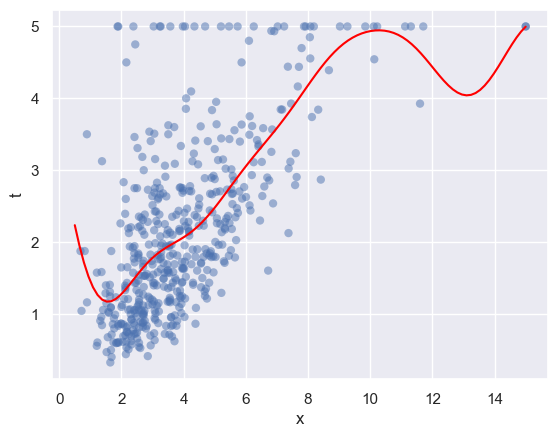

In [79]:
# TODO: plot the scatter of (x, t) and overlay the regression curve (x_new, t_new).
# Hint: use plot_scatter(x, t) and then sns.lineplot(x=x_new, y=t_new, color='red').
plot_scatter(x, t)
sns.lineplot(x=x_new, y=t_new, color='red')

## 1.4) Play around with the kernel $\sigma$. How does the fit look using $\sigma=1$ as compared to  $\sigma=10$?

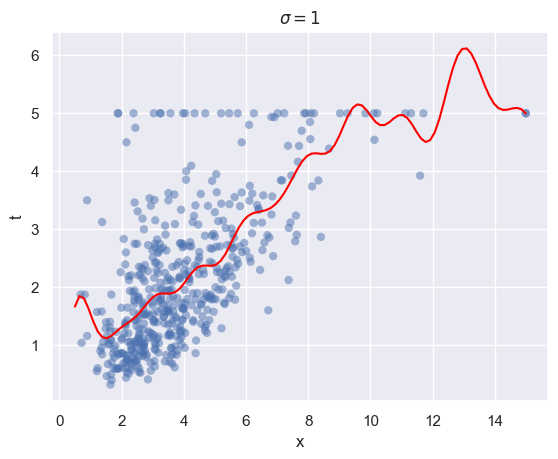

In [80]:
bandwidth = 1
K_bandwidth = gram_matrix(x, sigma=bandwidth)
alpha_bandwidth = np.linalg.solve(K_bandwidth + l * np.eye(N), t)
cross_kernel_bandwidth = gram_matrix(x_new, x, sigma=bandwidth)
t_new_bandwidth = cross_kernel_bandwidth @ alpha_bandwidth

plt.figure()
plot_scatter(x, t)
sns.lineplot(x=x_new, y=t_new_bandwidth, color='red')
plt.title(rf'$\sigma = {bandwidth}$')
plt.show()

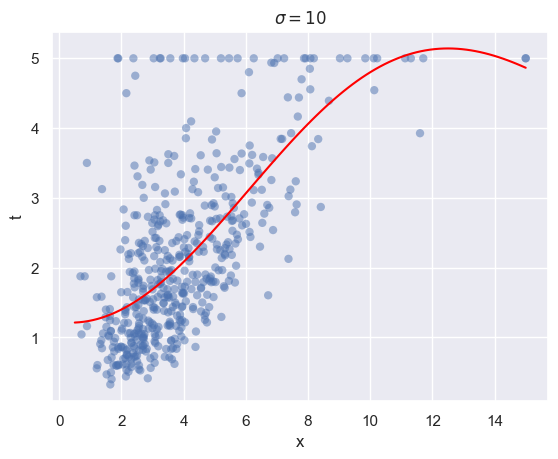

In [81]:
bandwidth = 10
K_bandwidth = gram_matrix(x, sigma=bandwidth)
alpha_bandwidth = np.linalg.solve(K_bandwidth + l * np.eye(N), t)
cross_kernel_bandwidth = gram_matrix(x_new, x, sigma=bandwidth)
t_new_bandwidth = cross_kernel_bandwidth @ alpha_bandwidth

plt.figure()
plot_scatter(x, t)
sns.lineplot(x=x_new, y=t_new_bandwidth, color='red')
plt.title(rf'$\sigma = {bandwidth}$')
plt.show()

With $\sigma=1$, the curve bends more because similarity falls off quickly, so each prediction responds more to nearby observations.  
With $\sigma=10$, similarity falls off more slowly, so observations farther away have more influence and the curve is smoother.